In [1]:
import jieba

# 1. 結合 MITRE ATT&CK 常見威脅手法與台灣資安新聞常用詞彙的自訂詞典
mitre_security_dict = [
    # 攻擊手法與惡意軟體 (MITRE Tactics/Techniques 相關詞彙)
    "勒索軟體",
    "阻斷服務攻擊",
    "DDoS",
    "釣魚郵件",
    "社交工程",
    "漏洞利用",
    "零日漏洞",
    "後門程式",
    "遠端存取木馬",
    "網頁殼",
    "供應鏈攻擊",
    "憑證竊取",
    "橫向移動",
    # 台灣在地資安情境常用詞
    "關鍵基礎設施",
    "資安事件",
    "通報應變",
    "駭客組織",
]

# 2. 將這些詞強制加入 jieba 詞庫中，權重設高以確保不會被切開
for word in mitre_security_dict:
    jieba.add_word(word, freq=2000, tag="SEC")

print("成功載入 MITRE 概念資安自訂詞典！")

# 測試斷詞效果
test_sentence = (
    "台灣某關鍵基礎設施遭到新型勒索軟體攻擊，駭客利用零日漏洞進行橫向移動。"
)
print("斷詞結果：", list(jieba.cut(test_sentence)))

Building prefix dict from the default dictionary ...
Loading model from cache C:\Users\guo79\AppData\Local\Temp\jieba.cache
Loading model cost 0.413 seconds.
Prefix dict has been built successfully.


成功載入 MITRE 概念資安自訂詞典！
斷詞結果： ['台灣', '某', '關鍵基礎設施', '遭到', '新型', '勒索軟體', '攻擊', '，', '駭客', '利用', '零日漏洞', '進行', '橫向移動', '。']


成功載入總計 10 筆跨平台新聞資料！

=== K-means 分群與平台交叉分析結果 ===

--- [Cluster 1] 核心攻擊主題 ---
  [iThome] 政府機關網站頻繁遭到境外阻斷服務攻擊，資安中心緊急應變
  * 平台分佈佔比: {'iThome': 1}

--- [Cluster 2] 核心攻擊主題 ---
  [TWCERT] TWCERT通報：某科技大廠內部系統遭到勒索軟體加密勒索
  [BleepingComputer] Taiwan semiconductor supply chain targeted by APT hacking group
  * 平台分佈佔比: {'BleepingComputer': 3, 'TWCERT': 2, 'iThome': 2}

--- [Cluster 3] 核心攻擊主題 ---
  [iThome] 台灣金融業傳出遭受大規模DDoS攻擊，伺服器面臨癱瘓危機
  [TWCERT] 資安署警告：針對關鍵基礎設施的釣魚郵件與社交工程攻擊增加
  * 平台分佈佔比: {'iThome': 1, 'TWCERT': 1}


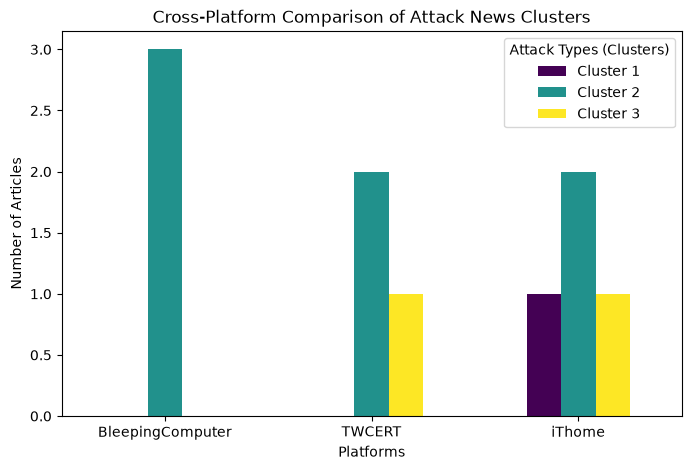


視覺化圖表已成功存檔至專案資料夾！


In [2]:
import jieba
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

# --- 1. 模擬載入三個平台的「台灣網路攻擊」新聞 Dataset ---
# （實作時，你可以將這部分替換成你用 requests / feedparser 從 A、B、C 平台抓回來的真實資料）
data = {
    "platform": ["iThome", "TWCERT", "BleepingComputer", "iThome", "TWCERT", "BleepingComputer", 
                 "iThome", "TWCERT", "BleepingComputer", "iThome"],
    "title": [
        "台灣金融業傳出遭受大規模DDoS攻擊，伺服器面臨癱瘓危機",
        "TWCERT通報：某科技大廠內部系統遭到勒索軟體加密勒索",
        "Taiwan semiconductor supply chain targeted by APT hacking group",
        "政府機關網站頻繁遭到境外阻斷服務攻擊，資安中心緊急應變",
        "利用未修補漏洞進行網頁漏洞利用與後門植入事件分析",
        "Phishing campaign targets Taiwan government agencies with malicious attachments",
        "台灣傳產大廠不幸中鏢勒索軟體，資料庫遭整台加密",
        "資安署警告：針對關鍵基礎設施的釣魚郵件與社交工程攻擊增加",
        "New zero-day vulnerability exploited in attacks against Taiwan institutions",
        "檢調破獲駭客集團透過遠端存取木馬入侵企業竊取憑證"
    ]
}

df = pd.DataFrame(data)
print(f"成功載入總計 {len(df)} 筆跨平台新聞資料！\n")

# --- 2. 使用 jieba 進行中文斷詞處理 ---
def tokenize_text(text):
    # 使用我們剛剛定義好包含 MITRE 詞彙的 jieba 進行斷詞，並過濾掉空白與單字元
    words = jieba.cut(text)
    return " ".join([w for w in words if len(w.strip()) > 1])

# 套用斷詞到整個 Dataset
df["cleaned_text"] = df["title"].apply(tokenize_text)

# --- 3. 使用 TF-IDF 將文字轉為數值矩陣 ---
vectorizer = TfidfVectorizer(max_features=100)
X = vectorizer.fit_transform(df["cleaned_text"])

# --- 4. 執行 K-means 演算法進行分群 (假設我們分 3 群) ---
num_clusters = 3
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
kmeans.fit(X)

# 將分群標籤存回 DataFrame
df["cluster"] = kmeans.labels_

# --- 5. 檢視分群結果與各平台的分布 ---
print("=== K-means 分群與平台交叉分析結果 ===")
for i in range(num_clusters):
    print(f"\n--- [Cluster {i+1}] 核心攻擊主題 ---")
    cluster_df = df[df["cluster"] == i]
    
    # 印出該群的前兩篇代表性新聞
    for idx, row in cluster_df.head(2).iterrows():
        print(f"  [{row['platform']}] {row['title']}")
        
    # 統計是哪一個平台最常報導這一群的內容
    platform_counts = cluster_df["platform"].value_counts().to_dict()
    print(f"  * 平台分佈佔比: {platform_counts}")

# --- 6. 視覺化：各平台在不同 K-means 群集中的分佈長條圖 ---
pivot_table = pd.crosstab(df["platform"], df["cluster"])
pivot_table.columns = [f"Cluster {i+1}" for i in pivot_table.columns]

pivot_table.plot(kind="bar", figsize=(8, 5), colormap="viridis")
plt.title("Cross-Platform Comparison of Attack News Clusters")
plt.xlabel("Platforms")
plt.ylabel("Number of Articles")
plt.xticks(rotation=0)
plt.legend(title="Attack Types (Clusters)")

# 自動將圖表存檔並顯示在筆記本中
plt.savefig("texting_cross_kmeans_platform_analysis.png", dpi=300, bbox_inches="tight")
plt.show()
print("\n視覺化圖表已成功存檔至專案資料夾！")